In [1]:
import random, numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
import matplotlib.pyplot as plt

In [2]:
random.seed(1)
np.random.seed(1)
text = open("data.txt").read().lower()

In [3]:
tokenizer = Tokenizer(oov_token="<oov>")
tokenizer.fit_on_texts([text])

words = tokenizer.word_index
vocab_size = len(words) + 1

tokens = tokenizer.texts_to_sequences([text])[0]

In [5]:
seq_len = 5
sequences = []

for i in range(seq_len, len(tokens)):
    seq = tokens[i-seq_len:i+1]
    sequences.append(seq)

sequences = np.array(sequences)
X, y = sequences[:,:-1], sequences[:,-1]

In [6]:
embed_dim = 50

model = Sequential([
    Embedding(vocab_size, embed_dim, input_length=seq_len),
    LSTM(64),
    Dense(vocab_size, activation="softmax")
])

C:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [7]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [8]:
history = model.fit(
    X, y,
    epochs=6,
    batch_size=16,
    verbose=1
)

Epoch 1/6
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.0129 - loss: 5.7095
Epoch 2/6
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0600 - loss: 5.6828
Epoch 3/6
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0521 - loss: 5.5248
Epoch 4/6
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0477 - loss: 5.2999
Epoch 5/6
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0476 - loss: 5.1737
Epoch 6/6
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0789 - loss: 5.1130


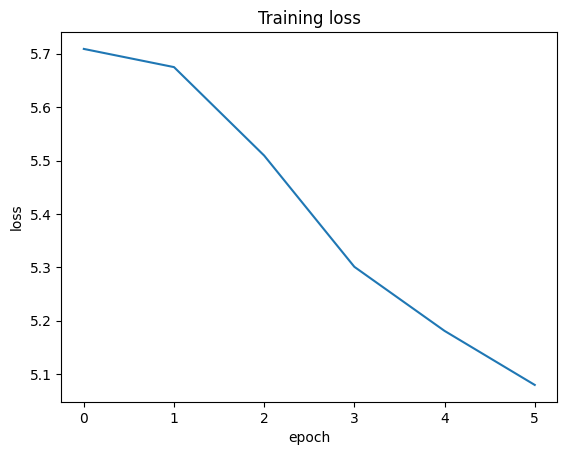

In [9]:
plt.plot(history.history["loss"])

plt.title("Training loss")
plt.xlabel("epoch")
plt.ylabel("loss")

plt.show()

In [10]:
def predict_next(seed_text, k=1):
    seed = seed_text.lower().split()[-seq_len:]
    while len(seed) < seq_len:
        seed = ["<oov>"] + seed
        
    seq = tokenizer.texts_to_sequences([" ".join(seed)])[0]
    pred = model.predict(np.array([seq]), verbose=0)[0]
    top = np.argsort(pred)[-k:][::-1]
    inv = {v:k for k,v in tokenizer.word_index.items()}
    
    return [inv.get(i, "<unk>") for i in top]

In [12]:
seeds = [
    "modern technology has become deeply",
    "students today rely heavily on",
    "the goal is to build a"
]

for s in seeds:
    print(s + " ->", predict_next(s, k=3))

modern technology has become deeply -> ['and', 'to', 'data']
students today rely heavily on -> ['and', 'data', 'to']
the goal is to build a -> ['and', 'data', 'to']
